# Lab 2: Music Genre Classification - CNNs
- **Task 1**: CNN trained from scratch on the mel spectrograms, trying different depths and numbers of filters.
- **Task 2**: ResNet18 pretrained on ImageNet (frozen embeddings + logistic regression, and full fine-tuning).
- **Research questions Q1, Q2 and Q5**, comparing against the Lab 1 models retrained on the same 80/20 split.

Requires an NVIDIA GPU: `pip install torch torchvision --index-url https://download.pytorch.org/whl/cu126` and `pip install pandas scikit-learn seaborn pillow`.

In [1]:
import os
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'  # needed for deterministic results on GPU

import time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings('ignore')

DATA_DIR = 'Data'
SEED = 42
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = DEVICE.type == 'cuda'  # mixed precision: about 2x faster on GPU
torch.use_deterministic_algorithms(True, warn_only=True)


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


print(torch.cuda.get_device_name(0) if AMP else 'No GPU found, training will be slow')

NVIDIA GeForce RTX 3050


## Loading the spectrograms
The PNGs (432×288) have a white matplotlib frame around the spectrogram, which is cropped. Two versions are built:
- **CNN from scratch**: grayscale at 109×168. The *magma* colormap is monotonic in brightness, so grayscale keeps the intensity.
- **ResNet18**: RGB at 224×224 with ImageNet normalisation.

There are 999 songs (`jazz.00054` is corrupted in GTZAN). Everything fits in GPU memory as float16 (~320 MB), so no `DataLoader` is needed.

In [2]:
CROP = (54, 35, 390, 253)  # box of the spectrogram inside the PNG
img_dir = os.path.join(DATA_DIR, 'images_original')
GENRES = sorted(g for g in os.listdir(img_dir) if os.path.isdir(os.path.join(img_dir, g)))

rows = []
for genre in GENRES:
    for fname in sorted(os.listdir(os.path.join(img_dir, genre))):
        if fname.endswith('.png'):
            song = fname.replace(genre, genre + '.').replace('.png', '.wav')  # blues00000.png -> blues.00000.wav
            rows.append({'path': os.path.join(img_dir, genre, fname), 'genre': genre, 'song': song})
meta = pd.DataFrame(rows)

y = LabelEncoder().fit_transform(meta['genre'])
images = [Image.open(p).convert('RGB').crop(CROP) for p in meta['path']]

gray = np.stack([np.array(im.convert('L').resize((168, 109))) for im in images])
gray = torch.tensor(gray)[:, None] / 255

rgb = np.stack([np.array(im.resize((224, 224))) for im in images])
rgb = torch.tensor(rgb).permute(0, 3, 1, 2) / 255
mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
rgb = (rgb - mean) / std

dtype = torch.float16 if AMP else torch.float32
X_small = gray.to(DEVICE, dtype)
X_224 = rgb.to(DEVICE, dtype)
Y = torch.tensor(y, device=DEVICE).long()
del images, gray, rgb
print(len(meta), 'songs |', tuple(X_small.shape), tuple(X_224.shape))

999 songs | (999, 1, 109, 168) (999, 3, 224, 224)


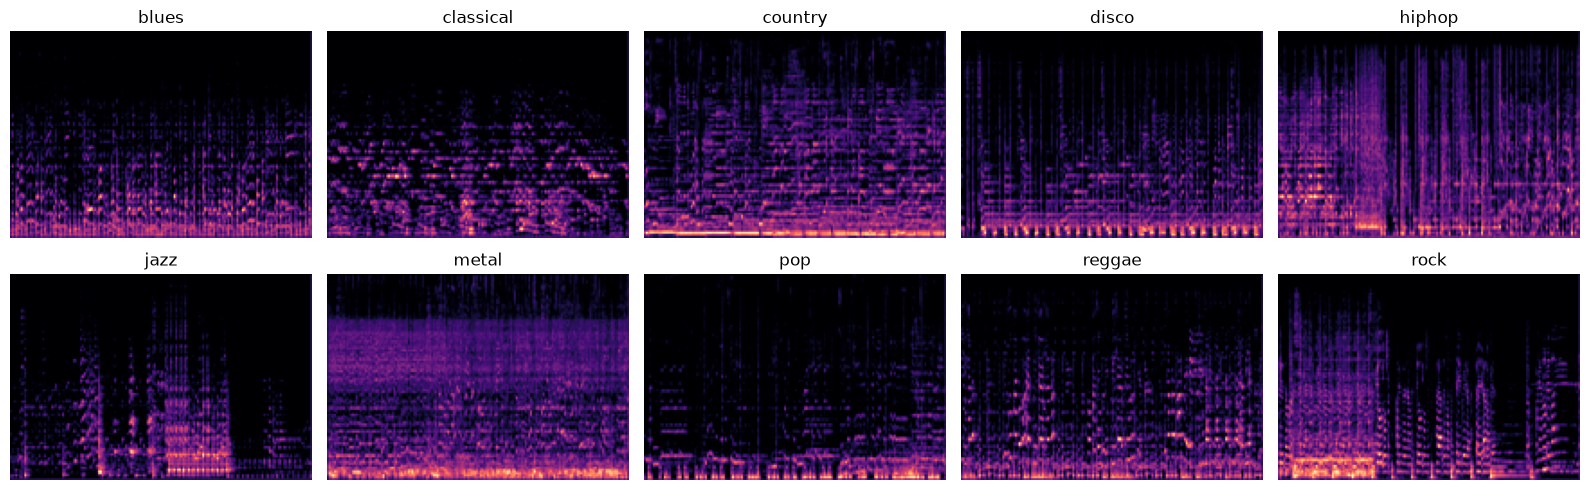

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(16, 5))
for ax, genre in zip(axes.flat, GENRES):
    i = meta.index[meta['genre'] == genre][0]
    ax.imshow(X_small[i, 0].float().cpu(), cmap='magma', aspect='auto')
    ax.set_title(genre)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 80/20 split and helpers
Stratified, shuffled split: 80% train / 20% test (200 songs). **Every model uses the same split.** To choose configurations without looking at the test set, the 80% is split again 80/20 into inner train / validation. Validation is also used for early stopping.

Training uses Adam + cross-entropy with a cosine learning-rate schedule and keeps the weights of the best validation epoch. As data augmentation, the spectrogram is circularly shifted in time. Flips are not used: reversing time or frequency makes no musical sense.

In [4]:
def make_split(seed):
    train_all, test = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=seed)
    train, val = train_test_split(train_all, test_size=0.2, stratify=y[train_all], random_state=seed)
    return train_all, train, val, test


idx_train, idx_tr, idx_val, idx_test = make_split(SEED)
y_test = y[idx_test]
results, test_preds = [], {}
print(f'Train {len(idx_train)} ({len(idx_tr)} + {len(idx_val)} val) | Test {len(idx_test)}')


def batches(X, idx, batch_size, shuffle=False):
    idx = torch.as_tensor(idx, device=DEVICE)
    if shuffle:
        idx = idx[torch.randperm(len(idx), device=DEVICE)]
    for i in range(0, len(idx), batch_size):
        b = idx[i:i + batch_size]
        yield X[b], Y[b]


@torch.no_grad()
def get_outputs(model, X, idx, batch_size=64):
    model.eval()
    outs = []
    for xb, _ in batches(X, idx, batch_size):
        with torch.autocast(DEVICE.type, enabled=AMP):
            outs.append(model(xb).float())
    return torch.cat(outs).cpu().numpy()


def predict(model, X, idx):
    return get_outputs(model, X, idx).argmax(1)


def n_params(model):
    return sum(p.numel() for p in model.parameters())


def train_model(model, X, train_idx, val_idx, epochs=60, lr=1e-3, patience=15, batch_size=32):
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    scaler = torch.amp.GradScaler(enabled=AMP)
    max_shift = X.shape[-1] // 4
    history, best_acc, best_epoch = [], -1, 0

    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in batches(X, train_idx, batch_size, shuffle=True):
            # The genre does not change if the song starts a few seconds earlier or later
            xb = torch.roll(xb, random.randint(-max_shift, max_shift), dims=-1)
            with torch.autocast(DEVICE.type, enabled=AMP):
                loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
        sched.step()

        val_acc = accuracy_score(y[val_idx], predict(model, X, val_idx))
        history.append(val_acc)
        if val_acc > best_acc:
            best_acc, best_epoch = val_acc, epoch
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        if epoch - best_epoch >= patience:
            break

    model.load_state_dict(best_state)
    return model, history, best_epoch, best_acc


def grid_eval(model, params, X, train_idx, test_idx):
    # Scaling + hyperparameter search with 5-fold CV inside train, then evaluation on test
    pipe = Pipeline([('scaler', StandardScaler()), ('clf', model)])
    grid = GridSearchCV(pipe, {f'clf__{k}': v for k, v in params.items()},
                        cv=StratifiedKFold(5, shuffle=True, random_state=SEED), n_jobs=-1)
    grid.fit(X[train_idx], y[train_idx])
    pred = grid.predict(X[test_idx])
    return grid, pred, accuracy_score(y[test_idx], pred)


def add_result(name, family, pred, params=np.nan, seconds=np.nan):
    test_preds[name] = pred
    results.append({'Model': name, 'Family': family, 'Test acc': accuracy_score(y_test, pred),
                    'Parameters': params, 'Train time (s)': seconds})

Train 799 (639 + 160 val) | Test 200


---
# Task 1: CNN from scratch
Each block is `Conv 3×3 → BatchNorm → ReLU → MaxPool 2×2`, doubling the number of filters at every block. The head is *Global Average Pooling* → Dropout → Linear. This avoids a huge dense layer and keeps the parameter count low, which matters with only ~640 training songs.

We try **2 to 5 convolutional layers** with **16 or 32 initial filters**, and pick the best one by **validation** accuracy.

In [5]:
def simple_cnn(n_conv, filters):
    layers, in_ch = [], 1
    for i in range(n_conv):
        out_ch = filters * 2**i
        layers += [nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(), nn.MaxPool2d(2)]
        in_ch = out_ch
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(in_ch, 10))


grid_rows, cnn_runs = [], {}
for n_conv in [2, 3, 4, 5]:
    for filters in [16, 32]:
        set_seed()
        start = time.time()
        model, history, epoch, acc = train_model(simple_cnn(n_conv, filters), X_small, idx_tr, idx_val)
        cnn_runs[n_conv, filters] = (model, history)
        grid_rows.append({'Conv layers': n_conv, 'Filters': filters, 'Parameters': n_params(model),
                          'Best epoch': epoch, 'Val acc': acc, 'Time (s)': time.time() - start})

# If two configurations tie on validation, the smaller one wins
grid_df = pd.DataFrame(grid_rows).sort_values(['Val acc', 'Parameters'], ascending=[False, True], ignore_index=True)
grid_df.round(3)

,Conv layers,Filters,Parameters,Best epoch,Val acc,Time (s)
0,4,16,98922,47,0.788,13.047
1,4,32,391370,51,0.781,23.340
2,5,32,1575114,45,0.775,25.410
3,5,16,395882,45,0.762,14.005
4,3,32,94410,50,0.731,20.581
5,3,16,24170,39,0.688,10.604
6,2,32,19658,29,0.556,12.218
7,2,16,5226,27,0.512,7.296


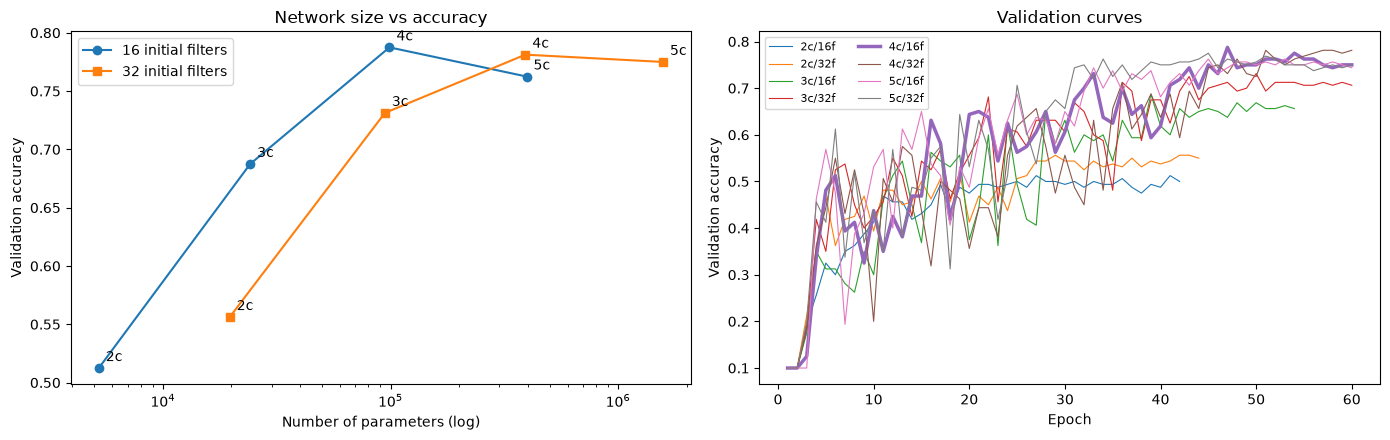

In [6]:
best_cfg = (int(grid_df.loc[0, 'Conv layers']), int(grid_df.loc[0, 'Filters']))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for filters, marker in [(16, 'o'), (32, 's')]:
    sub = grid_df[grid_df['Filters'] == filters].sort_values('Parameters')
    axes[0].plot(sub['Parameters'], sub['Val acc'], marker=marker, label=f'{filters} initial filters')
    for _, r in sub.iterrows():
        axes[0].annotate(f"{int(r['Conv layers'])}c", (r['Parameters'], r['Val acc']), textcoords='offset points', xytext=(5, 5))
axes[0].set(xscale='log', xlabel='Number of parameters (log)', ylabel='Validation accuracy', title='Network size vs accuracy')
axes[0].legend()

for cfg, (_, history) in cnn_runs.items():
    axes[1].plot(range(1, len(history) + 1), history, lw=2.5 if cfg == best_cfg else 0.8, label=f'{cfg[0]}c/{cfg[1]}f')
axes[1].set(xlabel='Epoch', ylabel='Validation accuracy', title='Validation curves')
axes[1].legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

Single evaluation of the chosen configuration on the test set:

In [7]:
best_row = grid_df.loc[0]
cnn_name = f'CNN {best_cfg[0]} layers / {best_cfg[1]} filters'
pred = predict(cnn_runs[best_cfg][0], X_small, idx_test)
add_result(cnn_name, 'CNN from scratch', pred, best_row['Parameters'], best_row['Time (s)'])
print(f'{cnn_name}: test acc = {accuracy_score(y_test, pred):.3f}')

CNN 4 layers / 16 filters: test acc = 0.765


---
# Task 2: pretrained ResNet18 (ImageNet)
1. **Frozen embeddings + logistic regression**: the network is only used to extract a 512-d vector per song (output of the global pooling), and a logistic regression is trained on top, as in Lab 1.
2. **Full fine-tuning**: the last layer is replaced by a 10-genre layer and the whole network is retrained with a low learning rate, so it does not forget what it already knows. Same validation set and early stopping as in Task 1.

In [8]:
backbone = torchvision.models.resnet18(weights='IMAGENET1K_V1', progress=False)
backbone.fc = nn.Identity()  # drop the ImageNet classifier, keep the 512-d embedding
start = time.time()
emb = get_outputs(backbone.to(DEVICE), X_224, np.arange(len(y)))
LOGREG_GRID = {'C': [0.001, 0.01, 0.1, 1]}
grid, pred, acc = grid_eval(LogisticRegression(max_iter=2000), LOGREG_GRID, emb, idx_train, idx_test)
add_result('ResNet18 frozen + LogReg', 'Pretrained (frozen)', pred, n_params(backbone), time.time() - start)
print(f'Frozen: CV acc = {grid.best_score_:.3f} {grid.best_params_} | test acc = {acc:.3f}')


def finetune(train_idx, val_idx, seed=SEED):
    set_seed(seed)
    model = torchvision.models.resnet18(weights='IMAGENET1K_V1', progress=False)
    model.fc = nn.Linear(512, 10)  # new head for the 10 genres
    return train_model(model, X_224, train_idx, val_idx, epochs=20, lr=1e-4, patience=5)


start = time.time()
ft_model, ft_history, epoch, val_acc = finetune(idx_tr, idx_val)
pred = predict(ft_model, X_224, idx_test)
add_result('ResNet18 fine-tuning', 'Pretrained (fine-tuning)', pred, n_params(ft_model), time.time() - start)
print(f'Fine-tuning: val acc = {val_acc:.3f} (epoch {epoch}) | test acc = {accuracy_score(y_test, pred):.3f}')
del backbone, ft_model
torch.cuda.empty_cache()

Frozen: CV acc = 0.667 {'clf__C': 0.01} | test acc = 0.745


Fine-tuning: val acc = 0.800 (epoch 8) | test acc = 0.810


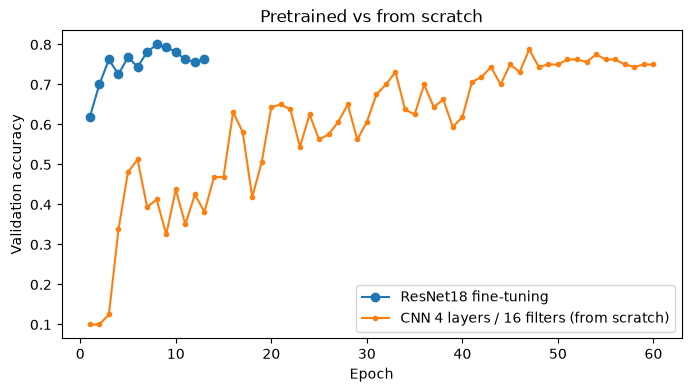

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(ft_history) + 1), ft_history, marker='o', label='ResNet18 fine-tuning')
cnn_history = cnn_runs[best_cfg][1]
plt.plot(range(1, len(cnn_history) + 1), cnn_history, marker='.', label=f'{cnn_name} (from scratch)')
plt.xlabel('Epoch')
plt.ylabel('Validation accuracy')
plt.title('Pretrained vs from scratch')
plt.legend()
plt.show()

---
# Research questions
First, the Lab 1 models are retrained on the **same split**: same algorithms and grids, on `features_30_sec.csv`, with 5-fold CV inside the 80% train set and evaluation on the same 200 test songs.

In [10]:
df30 = pd.read_csv(os.path.join(DATA_DIR, 'features_30_sec.csv')).set_index('filename')
df30 = df30.loc[meta['song']]  # same order as the images
assert (df30['label'].values == meta['genre'].values).all()
X_desc = df30.drop(columns=['label', 'length']).values

lab1_models = {
    'Logistic Regression': (LogisticRegression(max_iter=1000), {'C': [0.1, 1, 10]}),
    'k-NN': (KNeighborsClassifier(), {'n_neighbors': [3, 5, 7], 'weights': ['uniform', 'distance']}),
    'Decision Tree': (DecisionTreeClassifier(random_state=SEED), {'max_depth': [None, 10, 20], 'min_samples_split': [2, 5]}),
    'Random Forest': (RandomForestClassifier(random_state=SEED), {'n_estimators': [50, 100], 'max_depth': [None, 10]}),
    'ANN': (MLPClassifier(max_iter=500, random_state=SEED), {'hidden_layer_sizes': [(50,), (100,)], 'alpha': [0.0001, 0.001]}),
}

lab1_cv = {}
for name, (model, params) in lab1_models.items():
    start = time.time()
    grid, pred, acc = grid_eval(model, params, X_desc, idx_train, idx_test)
    lab1_cv[name] = grid.best_score_
    add_result(f'{name} (Lab 1)', 'Lab 1 descriptors', pred, seconds=time.time() - start)
    print(f'{name}: CV acc = {grid.best_score_:.3f} | test acc = {acc:.3f}')

# The best descriptor model is chosen by CV, not by looking at the test set
best_lab1 = max(lab1_cv, key=lab1_cv.get)
best_lab1_name = f'{best_lab1} (Lab 1)'
print('Best descriptor model (by CV):', best_lab1)

Logistic Regression: CV acc = 0.700 | test acc = 0.690


k-NN: CV acc = 0.687 | test acc = 0.630


Decision Tree: CV acc = 0.504 | test acc = 0.495


Random Forest: CV acc = 0.708 | test acc = 0.660


ANN: CV acc = 0.730 | test acc = 0.755
Best descriptor model (by CV): ANN


## Q1. Do learned features beat hand-crafted descriptors?
All models on the same 200 test songs (1 song = 0.5 points of accuracy).

,Model,Family,Test acc,Parameters,Train time (s)
0,ResNet18 fine-tuning,Pretrained (fine-tuning),0.810,"11,181,642",16.5
1,CNN 4 layers / 16 filters,CNN from scratch,0.765,"98,922",13.0
2,ANN (Lab 1),Lab 1 descriptors,0.755,-,8.6
3,ResNet18 frozen + LogReg,Pretrained (frozen),0.745,"11,176,512",11.4
4,Logistic Regression (Lab 1),Lab 1 descriptors,0.690,-,0.1
5,Random Forest (Lab 1),Lab 1 descriptors,0.660,-,1.3
6,k-NN (Lab 1),Lab 1 descriptors,0.630,-,0.3
7,Decision Tree (Lab 1),Lab 1 descriptors,0.495,-,0.2


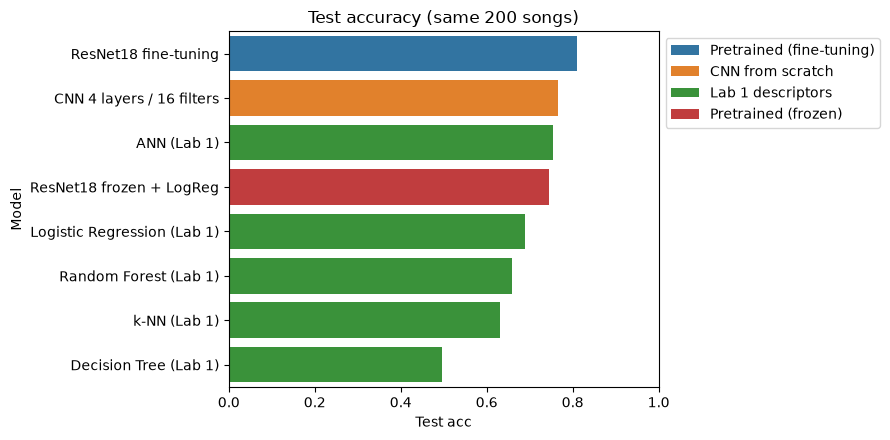

In [11]:
summary = pd.DataFrame(results).sort_values('Test acc', ascending=False, ignore_index=True)
display(summary.style.format({'Test acc': '{:.3f}', 'Parameters': '{:,.0f}', 'Train time (s)': '{:.1f}'}, na_rep='-'))

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=summary, y='Model', x='Test acc', hue='Family', dodge=False, ax=ax)
ax.set_xlim(0, 1)
ax.set_title('Test accuracy (same 200 songs)')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

**Answer Q1:** **Not clearly.** On the main split, the fine-tuned ResNet18 (0.810) beats the best descriptor model, the ANN (0.755), by 11 songs, but the CNN from scratch (0.765) wins by only 2 songs. Over 5 splits the ANN has the highest mean (0.745, against 0.730 and 0.725), and the gaps are within the noise. Learned features also need to be learned for this task: frozen ImageNet embeddings stay below the descriptors.

## Q2. Do CNNs and descriptor models make the same mistakes?
We compare the CNN from scratch, the fine-tuned ResNet18 and the best descriptor model: confusion matrices, error overlap and the most confused genre pairs.

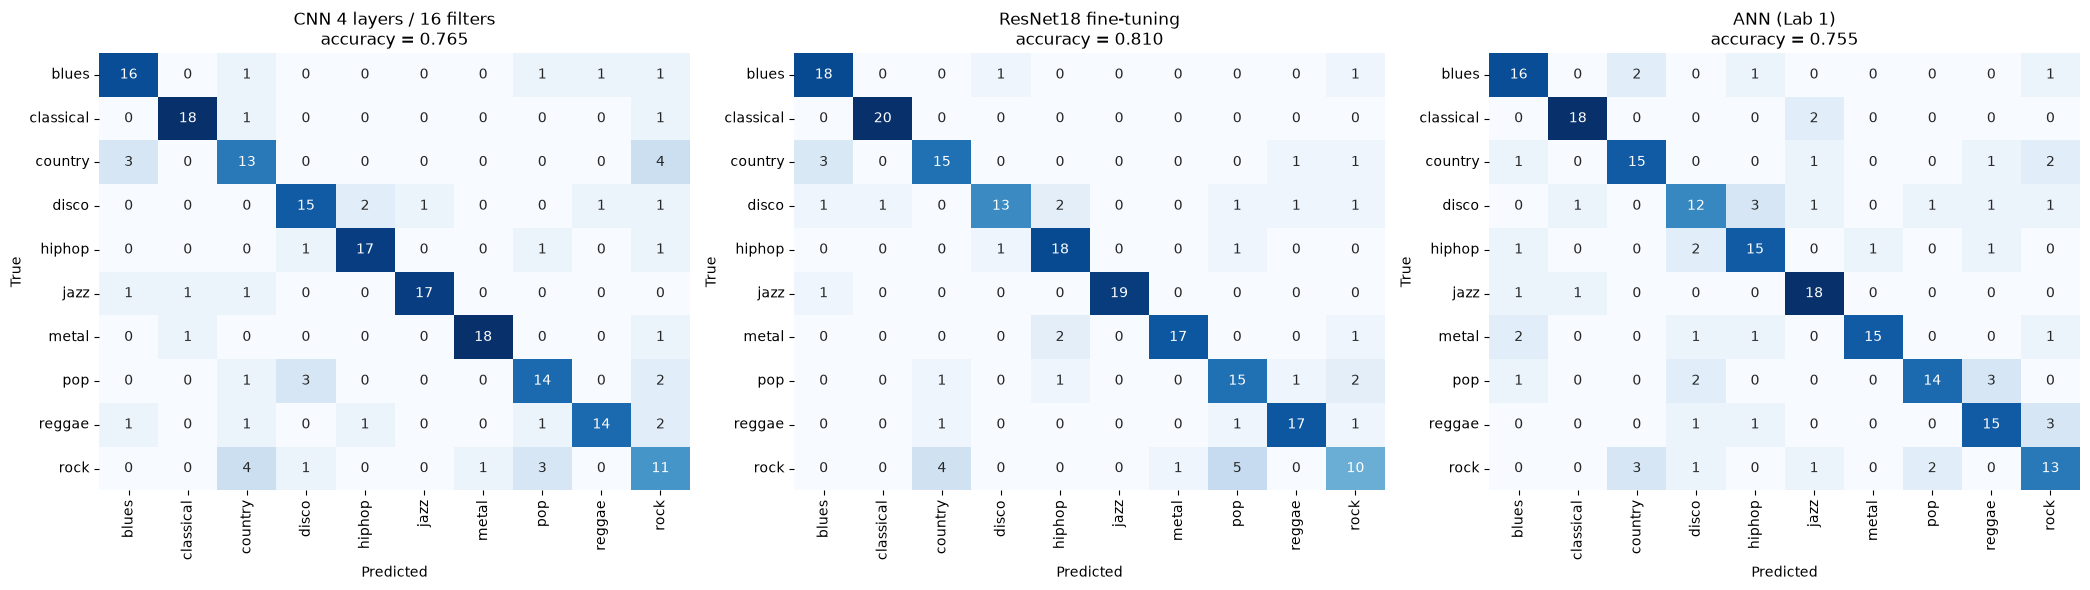

In [12]:
compared = [cnn_name, 'ResNet18 fine-tuning', best_lab1_name]
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, name in zip(axes, compared):
    cm = confusion_matrix(y_test, test_preds[name])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, xticklabels=GENRES, yticklabels=GENRES)
    ax.set(title=f'{name}\naccuracy = {accuracy_score(y_test, test_preds[name]):.3f}', xlabel='Predicted', ylabel='True')
plt.tight_layout()
plt.show()

In [13]:
errors = {name: test_preds[name] != y_test for name in compared}
overlap = []
for i, a in enumerate(compared):
    for b in compared[i + 1:]:
        both = (errors[a] & errors[b]).sum()
        either = (errors[a] | errors[b]).sum()
        overlap.append({'A': a, 'B': b, 'Errors A': errors[a].sum(), 'Errors B': errors[b].sum(),
                        'Both wrong': both, 'Jaccard': both / either,
                        'Oracle (one is right)': 1 - both / len(y_test)})
display(pd.DataFrame(overlap).round(3))


def top_confusions(pred, k=5):
    cm = confusion_matrix(y_test, pred)
    cm = cm + cm.T  # count the confusion in both directions
    pairs = [(cm[i, j], f'{GENRES[i]} ↔ {GENRES[j]}') for i in range(10) for j in range(i + 1, 10)]
    pairs.sort(reverse=True)
    return [f'{pair} ({n})' for n, pair in pairs[:k]]


pd.DataFrame({name: top_confusions(test_preds[name]) for name in compared}, index=range(1, 6))

,A,B,Errors A,Errors B,Both wrong,Jaccard,Oracle (one is right)
0,CNN 4 layers / 16 filters,ResNet18 fine-tuning,47,38,28,0.491,0.860
1,CNN 4 layers / 16 filters,ANN (Lab 1),47,49,25,0.352,0.875
2,ResNet18 fine-tuning,ANN (Lab 1),38,49,19,0.279,0.905


,CNN 4 layers / 16 filters,ResNet18 fine-tuning,ANN (Lab 1)
1,country ↔ rock (8),pop ↔ rock (7),disco ↔ hiphop (5)
2,pop ↔ rock (5),country ↔ rock (5),country ↔ rock (5)
3,blues ↔ country (4),disco ↔ hiphop (3),reggae ↔ rock (3)
4,disco ↔ pop (3),blues ↔ country (3),pop ↔ reggae (3)
5,disco ↔ hiphop (3),pop ↔ reggae (2),disco ↔ pop (3)


**Answer Q2:** **Only partly.** All three models confuse country ↔ rock, and rock is one of the hardest genres for all of them (10-13 out of 20). This looks like a property of the music, since these genres share instrumentation. The other errors depend on the model. The CNNs mostly confuse pop ↔ rock. The ANN confuses disco ↔ hiphop and pop ↔ reggae, genres with similar rhythm and energy. ResNet18 and the ANN are both wrong on only 19 songs. If we could pick the right model for each song, accuracy would reach 0.905, so combining them should help.

## Q5. How much does one 80/20 split tell you?
With 200 test songs, a difference between two models on a single split may just be noise. Everything is repeated with **5 different splits** (seeds 0-4), keeping each model's configuration fixed. The frozen embeddings are already computed, so only the logistic regression is retrained.

In [14]:
lab1_model, lab1_params = lab1_models[best_lab1]
seed_rows = []
for seed in range(5):
    train_all, tr, va, te = make_split(seed)
    set_seed(seed)
    cnn = train_model(simple_cnn(*best_cfg), X_small, tr, va)[0]
    ft = finetune(tr, va, seed)[0]

    accs = {
        cnn_name: accuracy_score(y[te], predict(cnn, X_small, te)),
        'ResNet18 fine-tuning': accuracy_score(y[te], predict(ft, X_224, te)),
        'ResNet18 frozen + LogReg': grid_eval(LogisticRegression(max_iter=2000), LOGREG_GRID, emb, train_all, te)[2],
        best_lab1_name: grid_eval(lab1_model, lab1_params, X_desc, train_all, te)[2],
    }
    for name, acc in accs.items():
        seed_rows.append({'Seed': seed, 'Model': name, 'Test acc': acc})
    print(seed, {name: round(acc, 3) for name, acc in accs.items()})

    del cnn, ft
    torch.cuda.empty_cache()

seed_df = pd.DataFrame(seed_rows)

0 {'CNN 4 layers / 16 filters': 0.725, 'ResNet18 fine-tuning': 0.745, 'ResNet18 frozen + LogReg': 0.665, 'ANN (Lab 1)': 0.795}


1 {'CNN 4 layers / 16 filters': 0.74, 'ResNet18 fine-tuning': 0.735, 'ResNet18 frozen + LogReg': 0.7, 'ANN (Lab 1)': 0.74}


2 {'CNN 4 layers / 16 filters': 0.72, 'ResNet18 fine-tuning': 0.665, 'ResNet18 frozen + LogReg': 0.685, 'ANN (Lab 1)': 0.715}


3 {'CNN 4 layers / 16 filters': 0.715, 'ResNet18 fine-tuning': 0.755, 'ResNet18 frozen + LogReg': 0.7, 'ANN (Lab 1)': 0.785}


4 {'CNN 4 layers / 16 filters': 0.725, 'ResNet18 fine-tuning': 0.75, 'ResNet18 frozen + LogReg': 0.66, 'ANN (Lab 1)': 0.69}


,mean,std,min,max,range (songs)
Model,,,,,
ANN (Lab 1),0.745,0.045,0.690,0.795,21
ResNet18 fine-tuning,0.730,0.037,0.665,0.755,18
CNN 4 layers / 16 filters,0.725,0.009,0.715,0.740,5
ResNet18 frozen + LogReg,0.682,0.019,0.660,0.700,8


,Mean diff vs Lab 1,Std diff,Wins (out of 5)
Model,,,
CNN 4 layers / 16 filters,-0.020,0.048,2
ResNet18 fine-tuning,-0.015,0.046,1
ResNet18 frozen + LogReg,-0.063,0.044,0


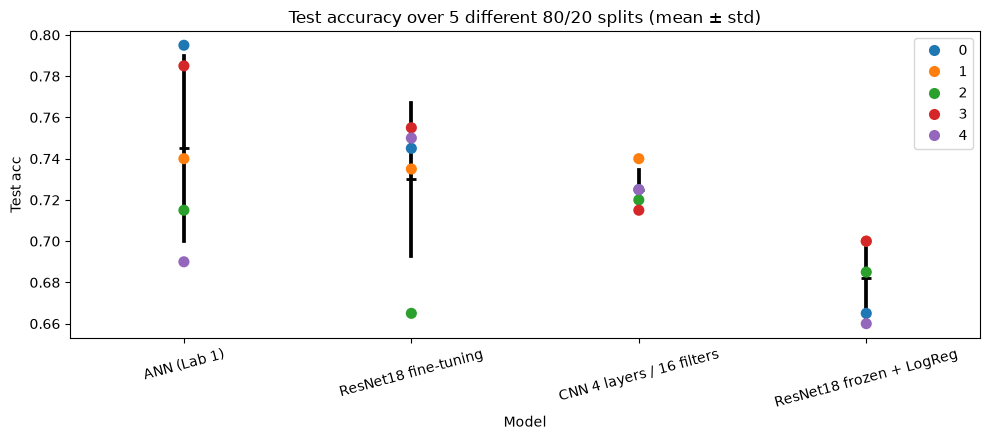

In [15]:
stats = seed_df.groupby('Model')['Test acc'].agg(['mean', 'std', 'min', 'max']).sort_values('mean', ascending=False)
stats['range (songs)'] = ((stats['max'] - stats['min']) * len(idx_test)).round().astype(int)
display(stats.round(3))

# Paired differences against the best descriptor model on each split
pivot = seed_df.pivot(index='Seed', columns='Model', values='Test acc')
diff = pivot.drop(columns=best_lab1_name).sub(pivot[best_lab1_name], axis=0)
display(pd.DataFrame({'Mean diff vs Lab 1': diff.mean(), 'Std diff': diff.std(), 'Wins (out of 5)': (diff > 0).sum()}).round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.stripplot(data=seed_df, x='Model', y='Test acc', order=stats.index, hue='Seed', palette='tab10', size=8, jitter=False, ax=ax)
sns.pointplot(data=seed_df, x='Model', y='Test acc', order=stats.index, color='black', markers='_', errorbar='sd', linestyles='none', ax=ax)
ax.set_title('Test accuracy over 5 different 80/20 splits (mean ± std)')
ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()

**Answer Q5:** **Very little.** Across 5 splits, the ANN ranges from 0.690 to 0.795 (21 songs) and the fine-tuned ResNet18 from 0.665 to 0.755. These ranges are larger than the gaps between models on a single split. The ranking even changes: on the main split fine-tuning is the best model, but it beats the ANN on only 1 of the 5 splits. The only result that holds on every split is that the frozen embeddings are worse (0.682).